<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/WEEK_17_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

PyTorch Version: 2.11.0+cpu
GPU Available: False


In [ ]:
a = torch.tensor([[1, 2], [3, 4]], dtype=torch.float32)
b = torch.ones((2, 2))
c = torch.zeros((2, 2))

print("Tensor A:\n", a)
print("Ones Tensor:\n", b)
print("Zeros Tensor:\n", c)
print("Addition:\n", a + b)
print("Matrix Multiplication:\n", torch.matmul(a, b))

Tensor A:
 tensor([[1., 2.],
        [3., 4.]])
Ones Tensor:
 tensor([[1., 1.],
        [1., 1.]])
Zeros Tensor:
 tensor([[0., 0.],
        [0., 0.]])
Addition:
 tensor([[2., 3.],
        [4., 5.]])
Matrix Multiplication:
 tensor([[3., 3.],
        [7., 7.]])


In [ ]:
x = torch.tensor(3.0, requires_grad=True)

y = x**2 + 2*x + 1

y.backward()

print("Value of y:", y.item())
print("Gradient dy/dx:", x.grad.item())

Value of y: 16.0
Gradient dy/dx: 8.0


In [ ]:
torch.manual_seed(42)

X = torch.linspace(-5, 5, 200).reshape(-1, 1)
y = 3 * X + 2 + 0.3 * torch.randn_like(X)

model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

losses = []

for epoch in range(200):
    predictions = model(X)
    loss = criterion(predictions, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Learned weight:", model.weight.item())
print("Learned bias:", model.bias.item())
print("Final loss:", losses[-1])

Learned weight: 2.9949026107788086
Learned bias: 1.9738152027130127
Final loss: 0.0878777876496315


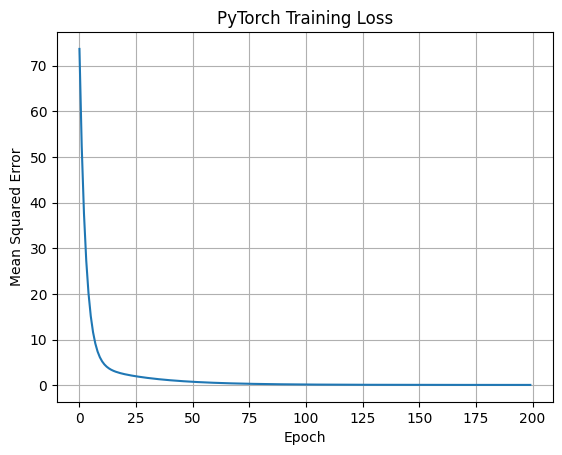

In [ ]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("PyTorch Training Loss")
plt.grid(True)
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.ToTensor()

train_data = torchvision.datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

classes = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Device: cpu


100%|██████████| 26.4M/26.4M [00:01<00:00, 19.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.0MB/s]

Training images: 60000
Testing images: 10000


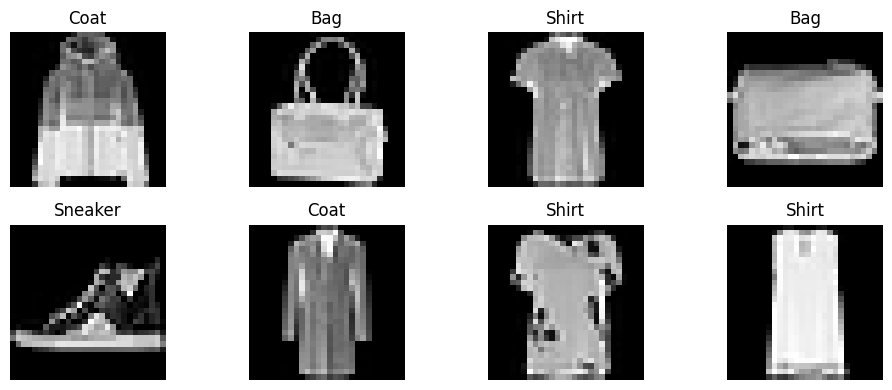

In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(classes[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
epochs = 5
train_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.4f}")

Epoch 1/5, Loss: 0.5819
Epoch 2/5, Loss: 0.3575
Epoch 3/5, Loss: 0.3099
Epoch 4/5, Loss: 0.2809
Epoch 5/5, Loss: 0.2580


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 89.64%


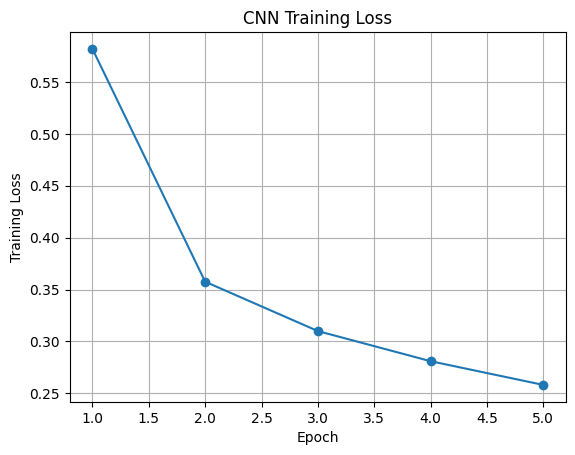

In [ ]:
plt.plot(range(1, epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

time = np.linspace(0, 100, 3000)
series = np.sin(time).astype(np.float32)

sequence_length = 20

X, y = [], []

for i in range(len(series) - sequence_length):
    X.append(series[i:i + sequence_length])
    y.append(series[i + sequence_length])

X = torch.tensor(np.array(X)).unsqueeze(-1)
y = torch.tensor(np.array(y)).unsqueeze(-1)

split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=64,
    shuffle=True
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2384
Testing samples: 596


In [ ]:
class SequenceModel(nn.Module):
    def __init__(self, model_type="RNN"):
        super().__init__()

        if model_type == "RNN":
            self.sequence_layer = nn.RNN(
                input_size=1,
                hidden_size=32,
                batch_first=True
            )
        elif model_type == "LSTM":
            self.sequence_layer = nn.LSTM(
                input_size=1,
                hidden_size=32,
                batch_first=True
            )
        elif model_type == "GRU":
            self.sequence_layer = nn.GRU(
                input_size=1,
                hidden_size=32,
                batch_first=True
            )

        self.output_layer = nn.Linear(32, 1)

    def forward(self, x):
        output, _ = self.sequence_layer(x)
        return self.output_layer(output[:, -1, :])

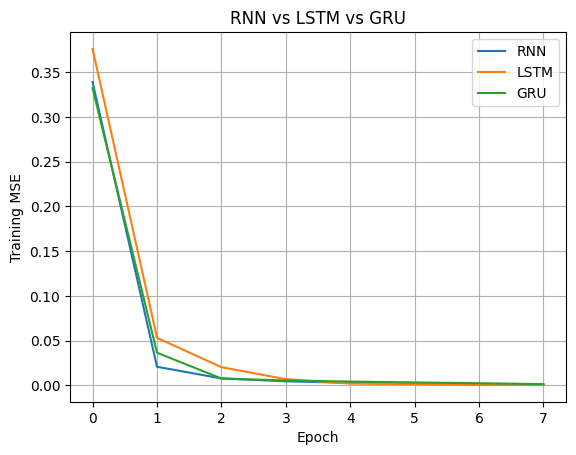

Test Mean Squared Error:
RNN: 0.000508
LSTM: 0.000257
GRU: 0.000759


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

results = {}
trained_models = {}
epochs = 8

for model_type in ["RNN", "LSTM", "GRU"]:
    model = SequenceModel(model_type).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        losses.append(total_loss / len(train_loader))

    model.eval()
    with torch.no_grad():
        predictions = model(X_test.to(device)).cpu()

    test_mse = nn.functional.mse_loss(predictions, y_test).item()

    results[model_type] = test_mse
    trained_models[model_type] = model

    plt.plot(losses, label=model_type)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("RNN vs LSTM vs GRU")
plt.legend()
plt.grid(True)
plt.show()

print("Test Mean Squared Error:")
for name, error in results.items():
    print(f"{name}: {error:.6f}")

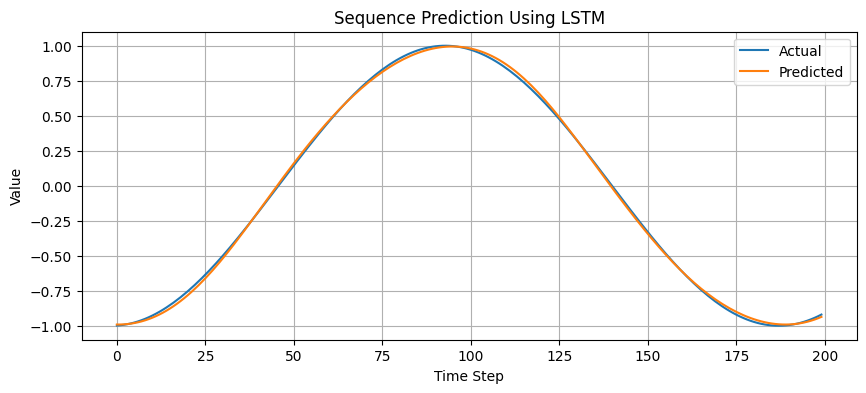

Best model for this experiment: LSTM


In [ ]:
best_model_name = min(results, key=results.get)
best_model = trained_models[best_model_name]

best_model.eval()

with torch.no_grad():
    predictions = best_model(X_test.to(device)).cpu().numpy()

plt.figure(figsize=(10, 4))
plt.plot(y_test.numpy()[:200], label="Actual")
plt.plot(predictions[:200], label="Predicted")

plt.xlabel("Time Step")
plt.ylabel("Value")
plt.title(f"Sequence Prediction Using {best_model_name}")
plt.legend()
plt.grid(True)
plt.show()

print("Best model for this experiment:", best_model_name)

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split

torch.manual_seed(42)

train_subset, val_subset = random_split(
    train_data,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

train_loader_reg = DataLoader(
    train_subset, batch_size=128, shuffle=True
)

val_loader_reg = DataLoader(
    val_subset, batch_size=128, shuffle=False
)

In [ ]:
class RegularizedNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

model = RegularizedNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
epochs = 20
patience = 3

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_state = None
wait = 0

for epoch in range(epochs):
    model.train()
    total_train_loss = 0

    for images, labels in train_loader_reg:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    train_loss = total_train_loss / len(train_loader_reg)
    train_losses.append(train_loss)

    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader_reg:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_val_loss += loss.item()

    val_loss = total_val_loss / len(val_loader_reg)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss={train_loss:.4f}, "
        f"Validation Loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping triggered.")
        break

if best_state is not None:
    model.load_state_dict(best_state)

Epoch 1: Train Loss=0.5563, Validation Loss=0.4711
Epoch 2: Train Loss=0.4049, Validation Loss=0.3779
Epoch 3: Train Loss=0.3696, Validation Loss=0.3328
Epoch 4: Train Loss=0.3461, Validation Loss=0.3273
Epoch 5: Train Loss=0.3263, Validation Loss=0.3186
Epoch 6: Train Loss=0.3101, Validation Loss=0.3238
Epoch 7: Train Loss=0.2989, Validation Loss=0.3430
Epoch 8: Train Loss=0.2902, Validation Loss=0.3116
Epoch 9: Train Loss=0.2783, Validation Loss=0.3055
Epoch 10: Train Loss=0.2704, Validation Loss=0.3093
Epoch 11: Train Loss=0.2652, Validation Loss=0.2969
Epoch 12: Train Loss=0.2570, Validation Loss=0.3014
Epoch 13: Train Loss=0.2472, Validation Loss=0.3055
Epoch 14: Train Loss=0.2478, Validation Loss=0.3191
Early stopping triggered.


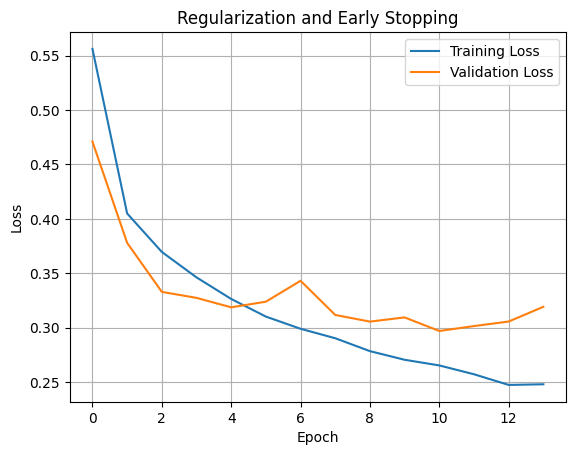

In [ ]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Regularization and Early Stopping")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loader_reg = DataLoader(
    test_data, batch_size=128, shuffle=False
)

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader_reg:
        images, labels = images.to(device), labels.to(device)

        predictions = model(images).argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Accuracy: 88.85%


In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = ResNet18_Weights.DEFAULT

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 labels: cat = 3, dog = 5
train_indices = [
    i for i, (_, label) in enumerate(train_data)
    if label in [3, 5]
]

test_indices = [
    i for i, (_, label) in enumerate(test_data)
    if label in [3, 5]
]

train_subset = Subset(train_data, train_indices)
test_subset = Subset(test_data, test_indices)

train_loader = DataLoader(
    train_subset, batch_size=32, shuffle=True
)

test_loader = DataLoader(
    test_subset, batch_size=32, shuffle=False
)

print("Training images:", len(train_subset))
print("Testing images:", len(test_subset))

100%|██████████| 170M/170M [32:41<00:00, 86.9kB/s]


Training images: 10000
Testing images: 2000


In [ ]:
model = resnet18(weights=weights)

# Freeze pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Replace the final layer for binary classification
model.fc = nn.Linear(model.fc.in_features, 2)

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


Linear(in_features=512, out_features=2, bias=True)


In [ ]:
epochs = 1  # Reduced epochs for quicker CPU verification
train_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)

        # Map cat=3 to 0 and dog=5 to 1
        labels = (labels == 5).long().to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        if batch_idx % 20 == 0:
            print(f"Epoch {epoch + 1} | Batch {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}")

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch + 1} Complete | Average Loss = {avg_loss:.4f}")

Epoch 1 | Batch 0/313 | Loss: 0.5202
Epoch 1 | Batch 20/313 | Loss: 0.3742
Epoch 1 | Batch 40/313 | Loss: 0.5384
Epoch 1 | Batch 60/313 | Loss: 0.4340
Epoch 1 | Batch 80/313 | Loss: 0.5514
Epoch 1 | Batch 100/313 | Loss: 0.2703
Epoch 1 | Batch 120/313 | Loss: 0.4313
Epoch 1 | Batch 140/313 | Loss: 0.3867
Epoch 1 | Batch 160/313 | Loss: 0.4622
Epoch 1 | Batch 180/313 | Loss: 0.3355
Epoch 1 | Batch 200/313 | Loss: 0.3505
Epoch 1 | Batch 220/313 | Loss: 0.2870
Epoch 1 | Batch 240/313 | Loss: 0.5134
Epoch 1 | Batch 260/313 | Loss: 0.3979
Epoch 1 | Batch 280/313 | Loss: 0.3063
Epoch 1 | Batch 300/313 | Loss: 0.3937
Epoch 1 Complete | Average Loss = 0.4177


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images = images.to(device)
        labels = (labels == 5).long().to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if batch_idx % 10 == 0:
            print(f"Evaluating batch {batch_idx}/{len(test_loader)}...")

print(f"Test Accuracy: {100 * correct / total:.2f}%")

Evaluating batch 0/63...
Evaluating batch 10/63...
Evaluating batch 20/63...
Evaluating batch 30/63...
Evaluating batch 40/63...
Evaluating batch 50/63...
Evaluating batch 60/63...
Test Accuracy: 83.30%


In [ ]:
import matplotlib.pyplot as plt

plt.plot(range(1, epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Transfer Learning with ResNet18")
plt.grid(True)
plt.show()